In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("used_cars.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (4009, 12)

Column names:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [5]:
# Find the mileage column
if "milage" in df.columns:
    mileage_col = "milage"
elif "mileage" in df.columns:
    mileage_col = "mileage"
else:
    raise ValueError("Mileage column not found. Check the column names.")

# Convert price to numbers
df["price"] = pd.to_numeric(
    df["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

# Convert mileage to numbers
df[mileage_col] = pd.to_numeric(
    df[mileage_col].astype(str).str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)

# Convert model year to numbers
df["model_year"] = pd.to_numeric(df["model_year"], errors="coerce")

# Remove rows without a valid target price
df = df.dropna(subset=["price"])

# Select the features used for prediction
features = [
    "brand",
    "model",
    "model_year",
    mileage_col,
    "fuel_type",
    "transmission"
]

# Keep only features available in the dataset
features = [col for col in features if col in df.columns]

df = df.drop_duplicates()

print("Cleaning completed!")
print("Selected features:", features)
print("Number of records:", len(df))

df[features + ["price"]].head()

Cleaning completed!
Selected features: ['brand', 'model', 'model_year', 'milage', 'fuel_type', 'transmission']
Number of records: 4009


,brand,model,model_year,milage,fuel_type,transmission,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,6-Speed A/T,10300
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,8-Speed Automatic,38005
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,Automatic,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,7-Speed A/T,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,8-Speed Automatic,34999


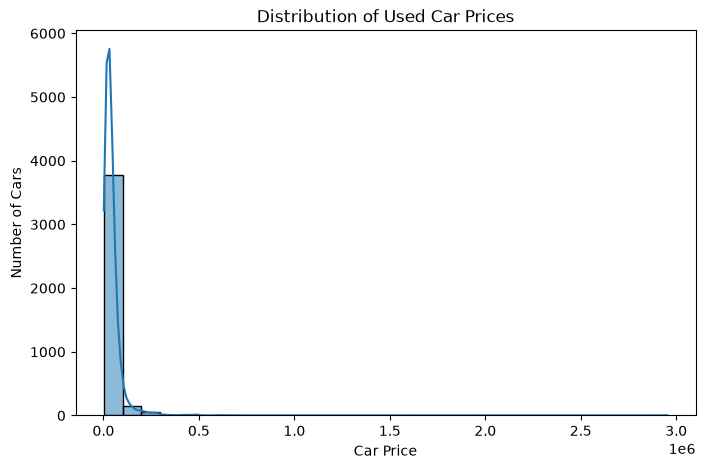

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.show()


In [7]:
X = df[features].copy()
y = df["price"].copy()

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    col for col in X.columns if col not in numeric_features
]

# Handle missing values and encode categories
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Data preparation completed!")

Training records: 3207
Testing records: 802
Data preparation completed!


In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print("Model training completed!")
results_df.round(2)

Model training completed!


,Model,MAE,RMSE,R2 Score
2,Random Forest,19252.83,134824.59,0.11
0,Linear Regression,24780.63,136391.88,0.09
1,Decision Tree,21508.43,136611.00,0.09


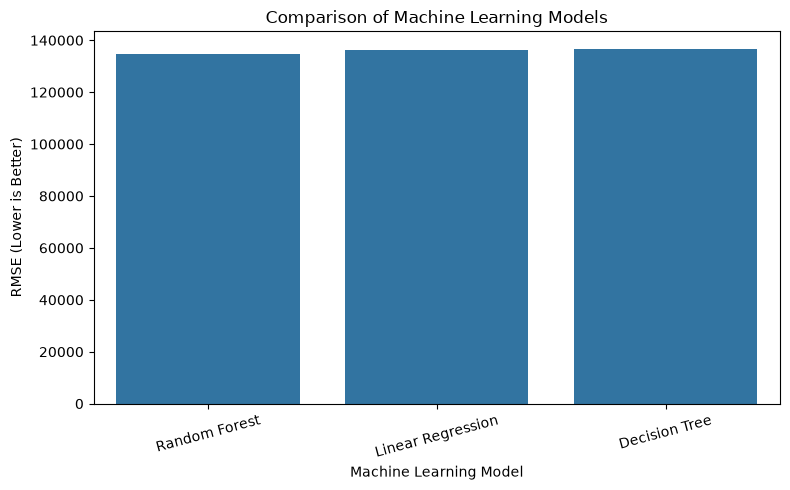

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(data=results_df, x="Model", y="RMSE")

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()